In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/raw/ev_sample_50k.csv")
df["Postal Code"] = (
    df["Postal Code"].astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)
df["Electric Range Usable"] = df["Electric Range"].where(df["Electric Range"] > 0)

df_wa = df.loc[
    (df["State"] == "WA") &
    df["Postal Code"].str.fullmatch(r"\d{5}").fillna(False)
].copy()
df_wa["Is BEV"] = df_wa["Electric Vehicle Type"] == "Battery Electric Vehicle (BEV)"
df_wa["Is PHEV"] = df_wa["Electric Vehicle Type"].str.contains("PHEV")

zip_summary = df_wa.groupby("Postal Code").agg(
    EV_Count=("DOL Vehicle ID", "count"),
    BEV_Count=("Is BEV", "sum"),
    PHEV_Count=("Is PHEV", "sum"),
    Avg_Model_Year=("Model Year", "mean"),
    Avg_Electric_Range=("Electric Range Usable", "mean"),
    Valid_Range_Count=("Electric Range Usable", "count")
).reset_index()
zip_summary["BEV_Percentage"] = (zip_summary["BEV_Count"] / zip_summary["EV_Count"] * 100).round(2)

print("Rows in sample:", len(df), "| WA rows kept:", len(df_wa))
print("ZIP codes:", len(zip_summary))
print(zip_summary["EV_Count"].describe())

Rows in sample: 50000 | WA rows kept: 49873
ZIP codes: 509
count     509.000000
mean       97.982318
std       150.941995
min         1.000000
25%         4.000000
50%        27.000000
75%       136.000000
max      1208.000000
Name: EV_Count, dtype: float64


ZIPs with fewer than 5 vehicles: 130 (26%)
ZIPs with fewer than 10 vehicles: 184 (36%)
ZIPs with fewer than 30 vehicles: 260 (51%)
Vehicles covered by ZIPs with 30+ vehicles: 47870 (96%)


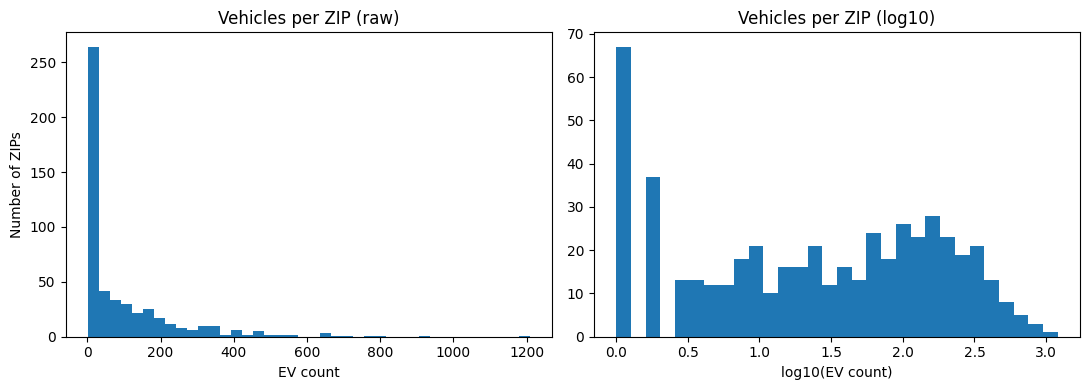

In [2]:
for n in [5, 10, 30]:
    k = (zip_summary["EV_Count"] < n).sum()
    print(f"ZIPs with fewer than {n} vehicles: {k} ({k/len(zip_summary):.0%})")

big = zip_summary[zip_summary["EV_Count"] >= 30]
print("Vehicles covered by ZIPs with 30+ vehicles:",
      big["EV_Count"].sum(), f"({big['EV_Count'].sum()/zip_summary['EV_Count'].sum():.0%})")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(zip_summary["EV_Count"], bins=40)
ax[0].set_title("Vehicles per ZIP (raw)")
ax[0].set_xlabel("EV count"); ax[0].set_ylabel("Number of ZIPs")
ax[1].hist(np.log10(zip_summary["EV_Count"]), bins=30)
ax[1].set_title("Vehicles per ZIP (log10)")
ax[1].set_xlabel("log10(EV count)")
plt.tight_layout()
plt.show()

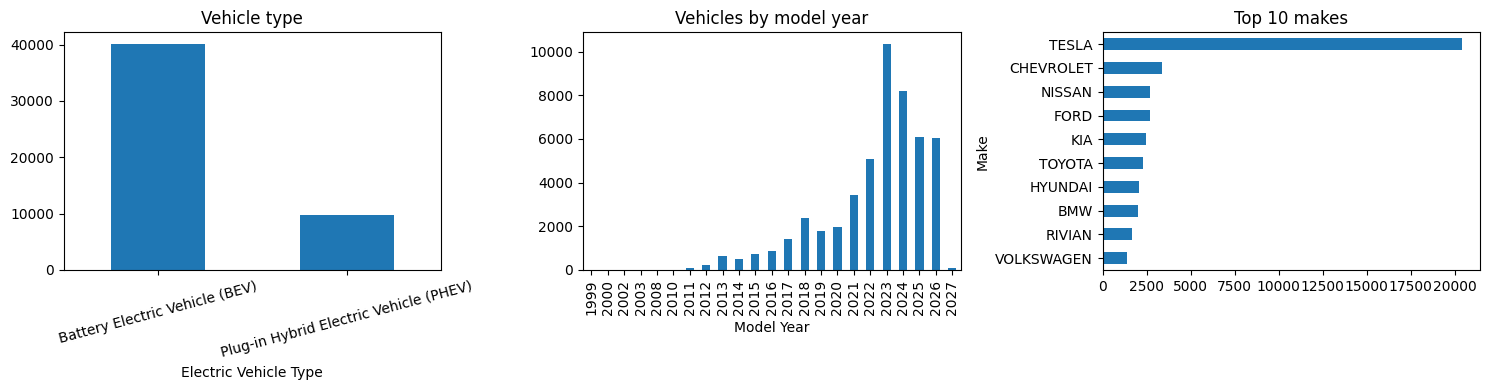

Share with Electric Range = 0 (unknown): 66%


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

df_wa["Electric Vehicle Type"].value_counts().plot(kind="bar", ax=ax[0])
ax[0].set_title("Vehicle type")
ax[0].tick_params(axis="x", rotation=15)

df_wa["Model Year"].value_counts().sort_index().plot(kind="bar", ax=ax[1])
ax[1].set_title("Vehicles by model year")

df_wa["Make"].value_counts().head(10).plot(kind="barh", ax=ax[2])
ax[2].set_title("Top 10 makes")
ax[2].invert_yaxis()

plt.tight_layout()
plt.show()

print("Share with Electric Range = 0 (unknown):",
      f"{df_wa['Electric Range Usable'].isna().mean():.0%}")

In [4]:
tab = df_wa.groupby("Model Year").agg(
    Vehicles=("DOL Vehicle ID", "count"),
    Zero_Range_Share=("Electric Range Usable", lambda s: s.isna().mean())
)
print(tab[tab["Vehicles"] >= 50].round(2))

print()
print(df_wa.groupby("Electric Vehicle Type")["Electric Range Usable"]
      .apply(lambda s: s.isna().mean()).round(2))

            Vehicles  Zero_Range_Share
Model Year                            
2011              99              0.00
2012             230              0.00
2013             660              0.00
2014             496              0.00
2015             709              0.00
2016             853              0.00
2017            1428              0.00
2018            2364              0.00
2019            1768              0.00
2020            1945              0.01
2021            3443              0.75
2022            5071              0.83
2023           10361              0.88
2024            8192              0.78
2025            6102              0.80
2026            6055              0.89
2027              83              0.96

Electric Vehicle Type
Battery Electric Vehicle (BEV)            0.81
Plug-in Hybrid Electric Vehicle (PHEV)    0.00
Name: Electric Range Usable, dtype: float64


ZIPs with 30+ vehicles: 249
                    EV_Count  BEV_Percentage  Avg_Model_Year  \
EV_Count                1.00            0.31            0.25   
BEV_Percentage          0.31            1.00            0.32   
Avg_Model_Year          0.25            0.32            1.00   
Avg_Electric_Range      0.13            0.66           -0.00   

                    Avg_Electric_Range  
EV_Count                          0.13  
BEV_Percentage                    0.66  
Avg_Model_Year                   -0.00  
Avg_Electric_Range                1.00  


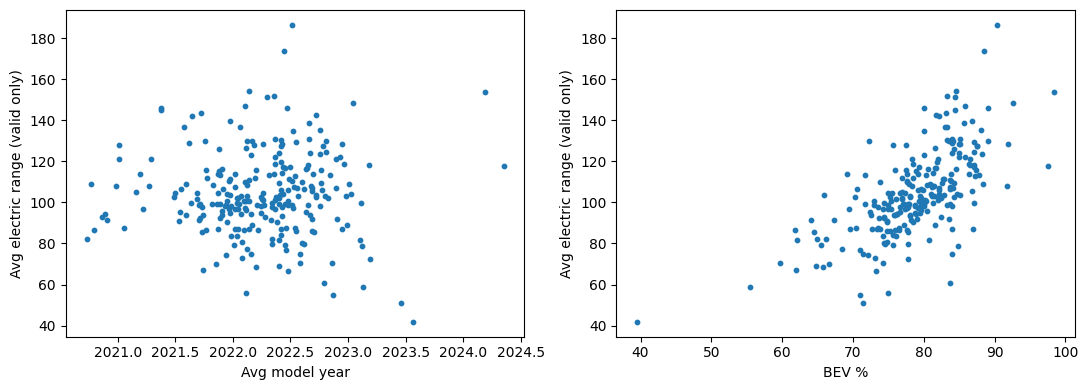

In [5]:
cols = ["EV_Count", "BEV_Percentage", "Avg_Model_Year", "Avg_Electric_Range"]
big = zip_summary[zip_summary["EV_Count"] >= 30]
print("ZIPs with 30+ vehicles:", len(big))
print(big[cols].corr().round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(big["Avg_Model_Year"], big["Avg_Electric_Range"], s=10)
ax[0].set_xlabel("Avg model year"); ax[0].set_ylabel("Avg electric range (valid only)")
ax[1].scatter(big["BEV_Percentage"], big["Avg_Electric_Range"], s=10)
ax[1].set_xlabel("BEV %"); ax[1].set_ylabel("Avg electric range (valid only)")
plt.tight_layout()
plt.show()

EDA Observations and Revised Questions

Observations**
1. After filtering to valid WA ZIPs, 49,873 of 50,000 sampled vehicles remain across 509 ZIP codes.
2. Vehicles per ZIP are heavily right skewed (median 27, max 1,208). 51% of ZIPs have fewer than 30 vehicles, but ZIPs with 30+ vehicles cover 96% of vehicles.
3. The fleet is about 80% BEV and 20% PHEV, concentrated in model years 2021-2026, and about 40% Tesla.
4. 66% of vehicles have no usable electric range. The zeros begin at model year 2021 (1% in 2020, 75% in 2021) and occur almost only in BEVs (81% of BEVs vs 0% of PHEVs). This looks like a recording pattern in the source data; the cause is not confirmed.
5. Among ZIPs with 30+ vehicles, average range correlates with BEV percentage (r = 0.66) but not with average model year (r = 0.00).
6. 6. The five largest ZIPs (98052, 98012, 98006, 98033, 98115) hold 697-1,208 vehicles each. BEV share is fairly even across counties (74%-83%), while Tesla share varies more (28%-47%). King County holds about half the sample.

Revised questions**
- Do ZIP-level clusters remain stable when ZIPs with fewer than 30 vehicles are excluded?
- Does clustering change when average electric range is dropped, given its overlap with BEV percentage and its missing values?
- Should EV_Count be log-transformed before scaling, given its skew?
- Because Tesla share is high everywhere, will association rules such as Tesla -> BEV be driven by base rates? Use lift, not confidence alone.

In [6]:
top_zip = zip_summary.sort_values("EV_Count", ascending=False).head(5)
print(top_zip[["Postal Code", "EV_Count", "BEV_Percentage", "Avg_Model_Year"]])

df_wa["Is Tesla"] = df_wa["Make"] == "TESLA"
county = df_wa.groupby("County").agg(
    Vehicles=("DOL Vehicle ID", "count"),
    BEV_Share=("Is BEV", "mean"),
    Tesla_Share=("Is Tesla", "mean")
)
print(county[county["Vehicles"] >= 500].round(2).sort_values("Tesla_Share"))

   Postal Code  EV_Count  BEV_Percentage  Avg_Model_Year
39       98052      1208           88.25     2022.759106
10       98012       926           88.44     2023.011879
5        98006       791           86.35     2022.962073
25       98033       767           85.01     2022.671447
66       98115       697           78.77     2021.977044
           Vehicles  BEV_Share  Tesla_Share
County                                     
Island          520       0.76         0.28
Whatcom        1244       0.76         0.28
Kitsap         1662       0.77         0.30
Thurston       1800       0.76         0.31
Skagit          578       0.78         0.32
Spokane        1464       0.74         0.35
Clark          3084       0.77         0.39
Pierce         4251       0.79         0.39
Benton          742       0.75         0.44
King          24097       0.83         0.44
Snohomish      6402       0.83         0.47
